# Khám phá dữ liệu chuyến bay Hoa Kỳ năm 2015

Phân tích mô tả tập dữ liệu chuyến bay nội địa Hoa Kỳ trong năm 2015, tập trung vào quy mô, cấu trúc biến, giá trị thiếu và phân bố thời gian trễ. Mục tiêu là nhận diện những đặc điểm nổi bật của dữ liệu và các điểm cần lưu ý khi diễn giải.

## Nguồn dữ liệu và phương pháp

Nguồn dữ liệu là `flights.csv`. Các cột được đọc theo schema khai báo tường minh; thống kê được tính trên toàn bộ bản ghi. Giá trị thiếu được giữ nguyên. Các phân vị được ước lượng bằng `approxQuantile` với relative error 0.0001.

Các giá trị cực đoan được giữ nguyên để tránh loại bỏ quan sát khi chưa có căn cứ nghiệp vụ. Phân tích này không thay thế dữ liệu thiếu, không cắt ngọn phân phối và không tạo tập dữ liệu đã biến đổi.

In [11]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT = next((p for p in candidates if (p / "results" / "eda_task2.json").is_file()), None)
if PROJECT is None:
    PROJECT = next((p / "spark-storage-benchmark" for p in candidates if (p / "spark-storage-benchmark" / "results" / "eda_task2.json").is_file()), None)
if PROJECT is None:
    raise FileNotFoundError("Không tìm thấy spark-storage-benchmark/results/eda_task2.json. Hãy mở notebook trong repository hoặc gán PROJECT tới thư mục spark-storage-benchmark.")

with (PROJECT / "results" / "eda_task2.json").open(encoding="utf-8") as f:
    profile = json.load(f)
meta = profile["metadata"]
row_count = meta["row_count"]
print(f"Quy mô dữ liệu: {row_count:,} dòng, {meta['column_count']} biến.")

Quy mô dữ liệu: 5,819,079 dòng, 31 biến.


## 1. Quy mô và cấu trúc

Schema được khai báo tường minh khi đọc dữ liệu. Bảng dưới đây nêu các nhóm trường chính; schema đầy đủ gồm 31 cột, trong đó có 26 cột `integer` và 5 cột `string`. Kiểm tra trùng lặp áp dụng trên toàn bộ bản ghi; không phát hiện bản ghi giống hệt nhau không đồng nghĩa với việc một khóa nghiệp vụ cụ thể là duy nhất.

In [12]:
type_counts = {}
for field in meta["schema"]:
    type_counts[field["type"]] = type_counts.get(field["type"], 0) + 1
size_bytes = meta["input_size_bytes"]
display(Markdown(
    f"| Đặc điểm | Giá trị |\n|---|---:|\n"
    f"| Dòng | {row_count:,} |\n"
    f"| Cột | {meta['column_count']} |\n"
    f"| Schema | {type_counts.get('int', 0)} integer, {type_counts.get('string', 0)} string |\n"
    f"| Dung lượng nguồn | {size_bytes:,} byte ({size_bytes / (1024 ** 2):.1f} MiB) |\n"
    f"| Dòng trùng hoàn toàn | {profile['duplicate_row_count']:,} |\n"
    f"| Mốc thời gian | 2015 |"
))
display(Markdown(
    "| Nhóm thông tin | Trường tiêu biểu | Kiểu dữ liệu |\n|---|---|---|\n"
    "| Thời gian | `YEAR`, `MONTH`, `DAY`, `DAY_OF_WEEK` | integer |\n"
    "| Hãng hàng không | `AIRLINE` | string |\n"
    "| Chuyến bay | `FLIGHT_NUMBER`, `TAIL_NUMBER` | integer, string |\n"
    "| Sân bay | `ORIGIN_AIRPORT`, `DESTINATION_AIRPORT` | string |\n"
    "| Thời gian trễ | `ARRIVAL_DELAY`, `DEPARTURE_DELAY` | integer |\n"
    "| Khoảng cách | `DISTANCE` | integer |\n"
    "| Trạng thái | `CANCELLED`, `DIVERTED`, `CANCELLATION_REASON` | integer, string |"
))
print(f"Spark {meta['spark_version']} · Python {meta['python_version']} · profile {meta['master']}")

| Đặc điểm | Giá trị |
|---|---:|
| Dòng | 5,819,079 |
| Cột | 31 |
| Schema | 26 integer, 5 string |
| Dung lượng nguồn | 592,406,591 byte (565.0 MiB) |
| Dòng trùng hoàn toàn | 0 |
| Mốc thời gian | 2015 |

| Nhóm thông tin | Trường tiêu biểu | Kiểu dữ liệu |
|---|---|---|
| Thời gian | `YEAR`, `MONTH`, `DAY`, `DAY_OF_WEEK` | integer |
| Hãng hàng không | `AIRLINE` | string |
| Chuyến bay | `FLIGHT_NUMBER`, `TAIL_NUMBER` | integer, string |
| Sân bay | `ORIGIN_AIRPORT`, `DESTINATION_AIRPORT` | string |
| Thời gian trễ | `ARRIVAL_DELAY`, `DEPARTURE_DELAY` | integer |
| Khoảng cách | `DISTANCE` | integer |
| Trạng thái | `CANCELLED`, `DIVERTED`, `CANCELLATION_REASON` | integer, string |

Spark 3.5.9 · Python 3.11.9 · profile local[2]


## 2. Giá trị thiếu và trạng thái chuyến bay

Tỷ lệ null tính trên toàn bộ số dòng. Các trường hãng, năm, tháng và khoảng cách không có giá trị thiếu. Các cột nguyên nhân delay null theo cùng một mẫu; biểu đồ dưới tập trung vào những trường giúp diễn giải ý nghĩa của giá trị thiếu.

| Trường | Số giá trị thiếu |
|---|---:|
| `AIRLINE` | 0 |
| `YEAR` | 0 |
| `MONTH` | 0 |
| `DISTANCE` | 0 |

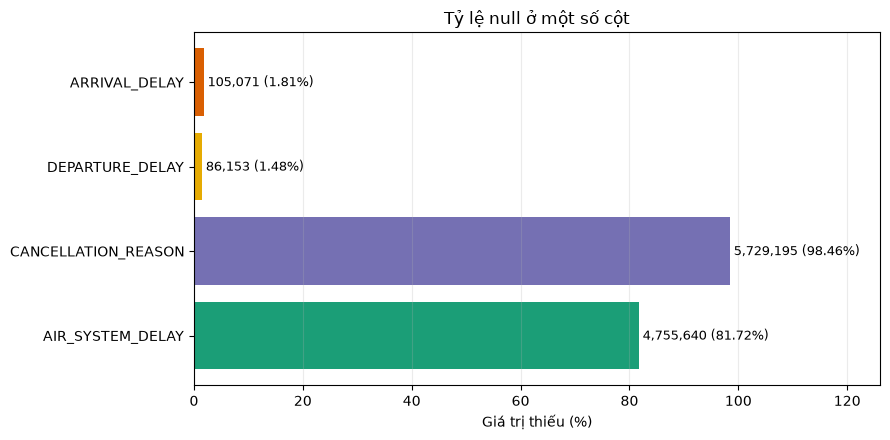

| Trạng thái | Số chuyến | Tỷ lệ |
|---|---:|---:|
| Bình thường | 5,714,008 | 98.19% |
| Chuyển hướng | 15,187 | 0.26% |
| Bị hủy | 89,884 | 1.54% |

Năm cột nguyên nhân delay cùng null: 4,755,640; cùng có giá trị: 1,063,439; null một phần: 0.

ARRIVAL_DELAY:
  Bình thường: 0/5,714,008 null
  Chuyển hướng: 15,187/15,187 null
  Bị hủy: 89,884/89,884 null

DEPARTURE_DELAY:
  Bình thường: 0/5,714,008 null
  Chuyển hướng: 0/15,187 null
  Bị hủy: 86,153/89,884 null

CANCELLATION_REASON:
  Bình thường: 5,714,008/5,714,008 null
  Chuyển hướng: 15,187/15,187 null
  Bị hủy: 0/89,884 null


In [13]:
null_counts = profile["null_counts"]
key_columns = ["AIRLINE", "YEAR", "MONTH", "DISTANCE"]
display(Markdown(
    "| Trường | Số giá trị thiếu |\n|---|---:|\n" + "\n".join(
        f"| `{name}` | {null_counts[name]:,} |" for name in key_columns
    )
))
selected = ["ARRIVAL_DELAY", "DEPARTURE_DELAY", "CANCELLATION_REASON", "AIR_SYSTEM_DELAY"]
null_pct = [100 * null_counts[name] / row_count for name in selected]
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(selected, null_pct, color=["#d95f02", "#e6ab02", "#7570b3", "#1b9e77"])
ax.set_xlabel("Giá trị thiếu (%)")
ax.set_title("Tỷ lệ null ở một số cột")
ax.invert_yaxis()
ax.grid(axis="x", alpha=0.25)
for bar, name, pct in zip(bars, selected, null_pct):
    ax.text(bar.get_width() + 0.7, bar.get_y() + bar.get_height()/2, f"{null_counts[name]:,} ({pct:.2f}%)", va="center", fontsize=9)
ax.set_xlim(0, max(null_pct) * 1.28)
plt.tight_layout()
plt.show()

status_labels = {(0, 0): "Bình thường", (0, 1): "Chuyển hướng", (1, 0): "Bị hủy"}
status_rows = profile["flight_status_counts"]
display(Markdown("| Trạng thái | Số chuyến | Tỷ lệ |\n|---|---:|---:|\n" + "\n".join(
    f"| {status_labels[(item['CANCELLED'], item['DIVERTED'])]} | {item['count']:,} | {item['count'] / row_count:.2%} |"
    for item in status_rows
)))
cause = profile["delay_cause_null_pattern"]
print(f"Năm cột nguyên nhân delay cùng null: {cause['all_null']:,}; cùng có giá trị: {cause['all_non_null']:,}; null một phần: {cause['partially_null']:,}.")
for column in ("ARRIVAL_DELAY", "DEPARTURE_DELAY", "CANCELLATION_REASON"):
    rows = profile["nulls_by_flight_status"][column]
    print(f"\n{column}:")
    for item in rows:
        label = status_labels[(item["CANCELLED"], item["DIVERTED"])]
        print(f"  {label}: {item['nulls']:,}/{item['rows']:,} null")

Toàn bộ chuyến bay bình thường có arrival delay; cột này null ở các chuyến bị hủy hoặc chuyển hướng. Ngược lại, `CANCELLATION_REASON` chỉ có giá trị ở các chuyến bị hủy. Các mẫu này cho thấy null không đồng nghĩa với lỗi dữ liệu; ý nghĩa phụ thuộc vào từng trường và trạng thái chuyến bay. Thay arrival delay null bằng 0 sẽ đánh đồng chuyến không có kết quả đến với chuyến đến đúng giờ, nên các giá trị thiếu được giữ nguyên.

## 3. Phân bố theo tháng và hãng hàng không

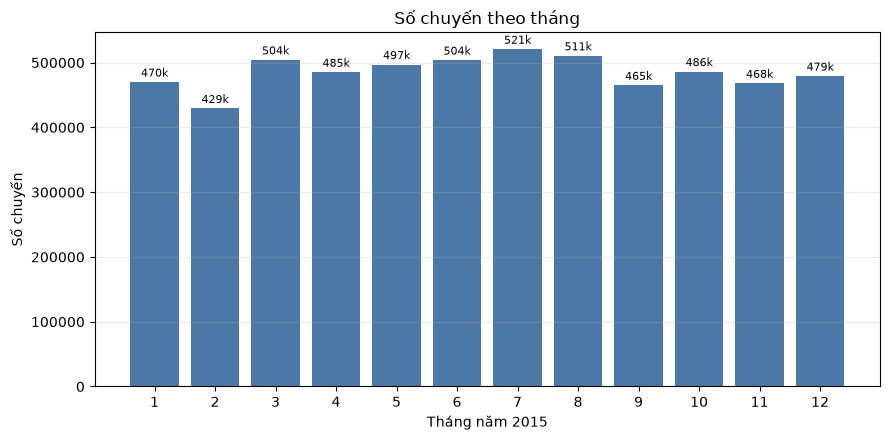

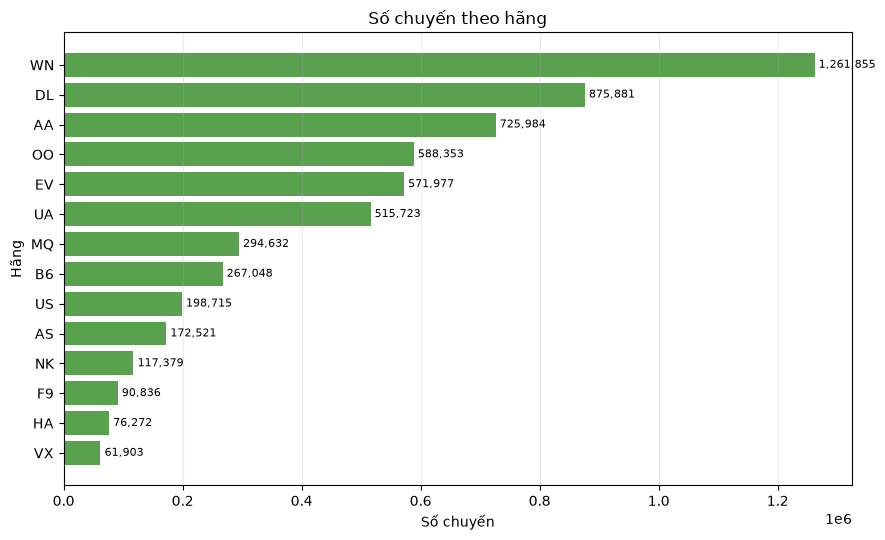

Thấp nhất: tháng 2 · 429,191; cao nhất: tháng 7 · 520,718; tỷ số 1.21×
Tháng 1: 469,968 chuyến (8.08%)
Hãng nhiều chuyến nhất: WN · 1,261,855; ít nhất: VX · 61,903.
Tỷ lệ số chuyến giữa hai hãng: 20.4×.


In [17]:
monthly = sorted(profile["year_month_counts"], key=lambda x: (x["YEAR"], x["MONTH"]))
months = [item["MONTH"] for item in monthly]
month_counts = [item["count"] for item in monthly]
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(months, month_counts, color="#4c78a8")
ax.set_xticks(months)
ax.set_xlabel("Tháng năm 2015")
ax.set_ylabel("Số chuyến")
ax.set_title("Số chuyến theo tháng")
ax.grid(axis="y", alpha=0.25)
ax.bar_label(bars, labels=[f"{n/1000:.0f}k" for n in month_counts], padding=2, fontsize=8)
plt.tight_layout()
plt.show()

carriers = sorted(profile["carrier_counts"], key=lambda x: x["count"])
fig, ax = plt.subplots(figsize=(9, 5.5))
bars = ax.barh([item["AIRLINE"] for item in carriers], [item["count"] for item in carriers], color="#59a14f")
ax.set_xlabel("Số chuyến")
ax.set_ylabel("Hãng")
ax.set_title("Số chuyến theo hãng")
ax.grid(axis="x", alpha=0.25)
ax.bar_label(bars, labels=[f"{item['count']:,}" for item in carriers], padding=3, fontsize=8)
plt.tight_layout()
plt.show()

low, high = min(monthly, key=lambda x: x["count"]), max(monthly, key=lambda x: x["count"])
jan = next(item for item in monthly if item["MONTH"] == 1)
print(f"Thấp nhất: tháng {low['MONTH']} · {low['count']:,}; cao nhất: tháng {high['MONTH']} · {high['count']:,}; tỷ số {high['count']/low['count']:.2f}×")
print(f"Tháng 1: {jan['count']:,} chuyến ({jan['count']/row_count:.2%})")
carrier_ratio = carriers[-1]["count"] / carriers[0]["count"]
print(f"Hãng nhiều chuyến nhất: {carriers[-1]['AIRLINE']} · {carriers[-1]['count']:,}; ít nhất: {carriers[0]['AIRLINE']} · {carriers[0]['count']:,}.")
print(f"Tỷ lệ số chuyến giữa hai hãng: {carrier_ratio:.1f}×.")

Toàn bộ bản ghi thuộc năm 2015 nên `YEAR` không có tính chọn lọc trong phạm vi bộ dữ liệu. Số chuyến giữa các tháng tương đối đồng đều.

`AIRLINE` có phân bố không đều: WN có 1,261,855 dòng, trong khi VX có 61,903 dòng, chênh khoảng 20.4×. Đây là dấu hiệu potential data skew, nhưng EDA chưa đủ để kết luận có runtime skew; cần kiểm tra chênh lệch task duration trong Spark UI.

### Điều kiện thời gian cho selective query

Bộ dữ liệu chỉ có `YEAR=2015`, nên `YEAR` không có tính chọn lọc. `MONTH` có 12 giá trị và phù hợp hơn cho selective query. Workload cố định của benchmark sử dụng `YEAR=2015 AND MONTH=1` (469,968 dòng, 8.08% tổng dữ liệu).

## 4. Thời gian trễ và khoảng cách

Các cột thời gian trễ có cả giá trị âm (đến/khởi hành sớm hơn lịch) và dương (trễ). Giá trị lớn nhất được đặt cạnh các phân vị để thể hiện phần đuôi của phân phối; độ lớn tự thân không chứng minh có lỗi dữ liệu.

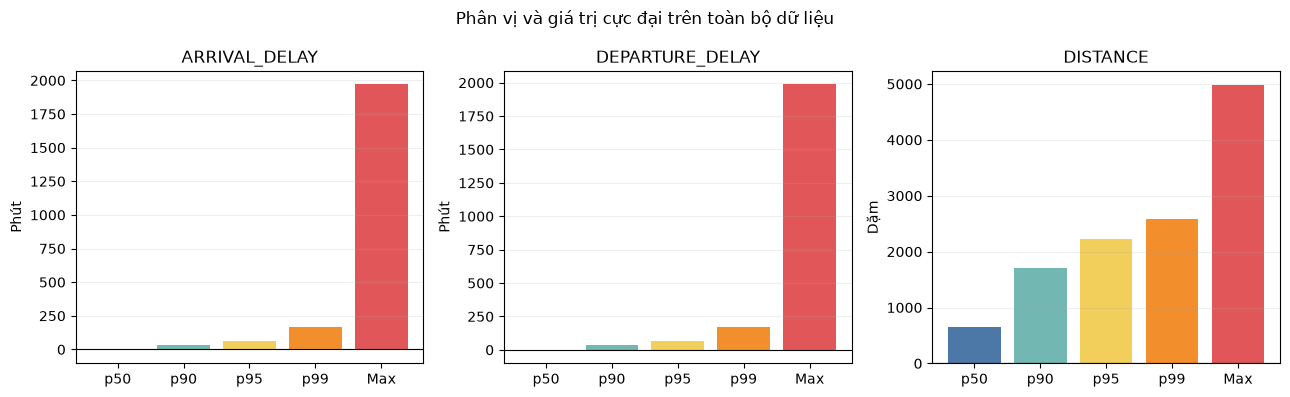

ARRIVAL_DELAY: n=5,714,008, min=-87, p50=-5.0, mean=4.41, p99=167.0, max=1971
DEPARTURE_DELAY: n=5,732,926, min=-82, p50=-2.0, mean=9.37, p99=168.0, max=1988
DISTANCE: n=5,819,079, min=21, p50=647.0, mean=822.36, p99=2588.0, max=4983


In [16]:
profile_names = ["ARRIVAL_DELAY", "DEPARTURE_DELAY", "DISTANCE"]
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, name in zip(axes, profile_names):
    stats = profile["delay_profiles"][name]
    q = stats["quantiles"]
    labels = ["p50", "p90", "p95", "p99", "Max"]
    values = [q["0.5"], q["0.9"], q["0.95"], q["0.99"], stats["max"]]
    ax.bar(labels, values, color=["#4c78a8", "#72b7b2", "#f2cf5b", "#f28e2b", "#e15759"])
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(name)
    ax.set_ylabel("Phút" if "DELAY" in name else "Dặm")
    ax.grid(axis="y", alpha=0.2)
plt.suptitle("Phân vị và giá trị cực đại trên toàn bộ dữ liệu")
plt.tight_layout()
plt.show()

for name in profile_names:
    stats = profile["delay_profiles"][name]
    q = stats["quantiles"]
    print(f"{name}: n={stats['non_null_count']:,}, min={stats['min']}, p50={q['0.5']}, mean={stats['mean']:.2f}, p99={q['0.99']}, max={stats['max']}")

Arrival delay có trung vị -5 phút nhưng trung bình 4.41 phút. Cùng với p99 là 167 phút và giá trị lớn nhất 1,971 phút, các thống kê này cho thấy phân phối có đuôi trễ dài. Giá trị cực đại cần được xem xét trong ngữ cảnh nghiệp vụ; riêng độ lớn chưa đủ để kết luận đó là lỗi.

## 5. Kết luận

- Bộ dữ liệu gồm 5,819,079 chuyến bay, 31 biến và bao phủ đủ 12 tháng năm 2015; không phát hiện dòng trùng hoàn toàn.
- Null ở thời gian trễ gắn với trạng thái chuyến bay. Đặc biệt, chuyến bị hủy hoặc chuyển hướng không có arrival delay quan sát được; không nên mặc định thay các giá trị này bằng 0.
- Số chuyến giữa các tháng tương đối ổn định, trong khi WN có khoảng 20.4 lần số chuyến của VX; đây là chênh lệch về tần suất bản ghi.
- Arrival delay có trung vị -5 phút nhưng trung bình 4.41 phút; p99 là 167 phút và giá trị lớn nhất là 1,971 phút, cho thấy phân phối có đuôi trễ dài.
- Giá trị cực đại cần được xem xét trong ngữ cảnh nghiệp vụ; chưa đủ căn cứ để coi đó là lỗi dữ liệu.

## 6. Hàm ý cho Task 2

Từ EDA, các workload phù hợp để kiểm tra gồm:

- **W1 — Broad scan:** dùng `AIRLINE` làm categorical key và `ARRIVAL_DELAY`, `DEPARTURE_DELAY`, `DISTANCE` làm measure cho aggregation.
- **W2 — Selective query:** bộ dữ liệu chỉ có `YEAR=2015`, nên `MONTH` có tính chọn lọc hơn. Workload benchmark sử dụng `YEAR=2015 AND MONTH=1`.
- **W3 — Narrow-column read:** bộ dữ liệu có 31 cột, nhưng workload chỉ cần `AIRLINE` và `ARRIVAL_DELAY`; phù hợp để kiểm tra việc đọc một subset cột.
- Phân bố `AIRLINE` không đều là dấu hiệu potential data skew cần theo dõi khi thực thi workload.
- Các giá trị null của delay có ý nghĩa dữ liệu và không nên tự động chuyển thành 0.